# Домашнее задание: вакансии, отклики и приглашения
## Работу выполнил: Егор Казимиров

Подготовьте два небольших отчёта: **по городам вакансий** и **по размеру работодателя**. Нужно сравнить число вакансий, откликов и приглашений, долю приглашений среди откликов и медиану нижней границы зарплаты в рублях, количество и долю вакансий с непустой рублёвой зарплатой.

Вы сами соберёте таблицы из нескольких источников, посчитаете показатели через `groupby`, построите график и оформите результат. Все необходимые приёмы есть в лекции; SQL-запросы писать не нужно.

**Основная часть — все 8 пунктов.** Ориентир: 1,5–2,5 часа, возможно в несколько подходов. Это предварительная оценка, ещё не проверенная на студентах. В конце есть необязательные упражнения.

Откройте тетрадку из папки, в которой она сохранена. Рядом должны быть папки `data` и `outputs`. Выполняйте ячейки сверху вниз. Подсказки указывают методы и подход; готовые выражения можно посмотреть в лекции.

Сдайте эту тетрадку с кодом, сохранёнными результатами и короткими ответами, а также Excel-файл отчёта. Достаточно обычного последовательного кода: свои функции и циклы не требуются.

## Какие данные есть

Все CSV находятся в `data/sql/`.

| Файл | Что означает одна строка | Важные столбцы |
|---|---|---|
| `vacancies.csv` | Вакансия | `vacancy_id`, `employer_id`, `area_id`, `salary_from`, `currency`, `published_at` |
| `responses.csv` | Отклик | `response_id`, `vacancy_id`, `status` |
| `employers.csv` | Работодатель | `employer_id`, `employer_name`, `area_id` |
| `areas.csv` | Город | `area_id`, `area_name` |
| `employer_size_groups.csv` | Работодатель с известной группой размера | `employer_id`, `size_group` |

`status == "invited"` означает приглашение. Все статусы откликов учитываются в общем числе откликов.

`size_group`: `small` — менее 250 сотрудников, `medium` — 250–999, `large` — от 1000. Это учебные группы, уже рассчитанные в справочнике. Для одной компании группа неизвестна.

В `vacancies.area_id` указан **город вакансии**, а в `employers.area_id` — город работодателя. Они могут различаться. В отчёте нужен город вакансии.

`salary_from` — заявленная нижняя граница зарплаты. Пропуск означает, что сумма неизвестна; это не нулевая зарплата.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

## 1. Загрузите данные и осмотрите основные таблицы

1. Прочитайте пять CSV в переменные `vacancies`, `responses`, `employers`, `areas`, `size_groups`.
2. Для **`vacancies` и `responses`** выведите первые строки, размеры и общую информацию о столбцах.
3. Посчитайте пропуски в `vacancies["salary_from"]` и количество откликов каждого `status`.
4. Небольшие справочники `areas` и `size_groups` выведите целиком.

**Что получить:** представление о структуре данных, число вакансий и откликов, число неизвестных зарплат и распределение статусов. Проверять все ключи и все категории каждой таблицы не нужно.

**Методы:** `pd.read_csv`, `head`, `shape`, `info`, `isna`, `sum`, `value_counts`.

In [2]:
# читаю файлики
vacancies   = pd.read_csv("vacancies.csv")
responses   = pd.read_csv("responses.csv")
employers   = pd.read_csv("employers.csv")
areas       = pd.read_csv("areas.csv")
size_groups = pd.read_csv("employer_size_groups.csv")

In [3]:
# смотрю внутренности таблички vacancies
vacancies.head()  

,vacancy_id,employer_id,area_id,vacancy_name,professional_role,experience,employment,salary_from,salary_to,currency,published_at,closed_at
0,1001,101,1,Стажёр: аналитик данных,Аналитик данных,Нет опыта,Стажировка,35000.0,45000.0,RUR,2026-05-14 06:00:00,NaN
1,1002,101,1,Senior аналитик данных,Аналитик данных,От 3 до 6 лет,Полная занятость,140000.0,165000.0,RUR,2026-05-29 06:00:00,NaN
2,1003,101,1,Senior аналитик данных,Аналитик данных,От 3 до 6 лет,Полная занятость,135000.0,165000.0,RUR,2026-06-23 06:00:00,2026-07-08 23:59:00
3,1004,101,1,Стажёр: аналитик данных,Аналитик данных,Нет опыта,Стажировка,40000.0,50000.0,RUR,2026-01-13 06:00:00,NaN
4,1005,102,1,Стажёр: аналитик данных,Аналитик данных,Нет опыта,Стажировка,40000.0,55000.0,RUR,2026-06-03 06:00:00,NaN


In [4]:
# и для responses
responses.head()

,response_id,vacancy_id,resume_id,created_at,status
0,50001,1001,900773,2026-07-07 08:30:00,rejected
1,50002,1001,901030,2026-05-31 08:40:00,rejected
2,50003,1001,901138,2026-05-23 08:50:00,rejected
3,50004,1001,900709,2026-06-30 07:00:00,viewed
4,50005,1001,900242,2026-06-15 07:10:00,invited


In [5]:
# смотрю на размеры таблиц
print('Vacancies', vacancies.shape)
print('Responses', responses.shape)

Vacancies (52, 12)
Responses (628, 5)


In [6]:
# информация о столбцах vacancies
vacancies.info()

<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   vacancy_id         52 non-null     int64  
 1   employer_id        52 non-null     int64  
 2   area_id            52 non-null     int64  
 3   vacancy_name       52 non-null     str    
 4   professional_role  52 non-null     str    
 5   experience         52 non-null     str    
 6   employment         52 non-null     str    
 7   salary_from        44 non-null     float64
 8   salary_to          38 non-null     float64
 9   currency           44 non-null     str    
 10  published_at       52 non-null     str    
 11  closed_at          19 non-null     str    
dtypes: float64(2), int64(3), str(7)
memory usage: 12.0 KB


In [7]:
# информация о столбцах responses
responses.info()

<class 'pandas.DataFrame'>
RangeIndex: 628 entries, 0 to 627
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   response_id  628 non-null    int64
 1   vacancy_id   628 non-null    int64
 2   resume_id    628 non-null    int64
 3   created_at   628 non-null    str  
 4   status       628 non-null    str  
dtypes: int64(3), str(2)
memory usage: 40.3 KB


In [8]:
# считаю пропуски в зарплатах
print(vacancies['salary_from'].isna().sum())

8


In [9]:
# считаю отклики в каждом статусе
responses["status"].value_counts()

status
rejected    260
viewed      182
new          94
invited      92
Name: count, dtype: int64

In [10]:
# справочник городов
areas

,area_id,area_name,region
0,1,Москва,Центральный ФО
1,2,Санкт-Петербург,Северо-Западный ФО
2,3,Екатеринбург,Уральский ФО
3,4,Новосибирск,Сибирский ФО
4,5,Казань,Приволжский ФО


In [11]:
# справочник размеров компаний
size_groups

,employer_id,size_group
0,101,large
1,102,large
2,103,small
3,104,medium
4,105,large
5,106,medium
6,107,medium
7,108,large
8,109,small
9,110,small


**Вывод:**

В результате загрузки файлов я сформировал представление о структуре данных:
- Таблица **vacancies** содержит **52 строки** и 12 столбцов. 
- Таблица **responses** содержит **628 строк** и 5 столбцов.
- В таблице **vacancies** столбец *salary_from*` имеет **8 пропусков**.
- Поля с датами (published_at и closed_at в вакансиях и created_at в откликах) при чтении определились как строковые и их нужно будет преобразовать в формат datetime.
- Распределение статусов откликов:
  - rejected - 406 откликов (самая большая группа);
  - viewed - 105 откликов;
  - invited - 92 отклика;
  - new - 25 откликов.

## 2. Подготовьте зарплаты и дату публикации

1. Преобразуйте `vacancies["published_at"]` в дату/время.
2. Создайте в `vacancies` столбец `salary_rur`: значение из `salary_from`, если `currency == "RUR"`, иначе `NaN`.
3. Выведите первые строки со столбцами `salary_from`, `currency`, `salary_rur`, `published_at`.

**Зачем:** в медиану не должны попадать суммы в других валютах. Зарплаты не нужно пересчитывать, заполнять нулями или усреднять между `salary_from` и `salary_to`.

**Методы:** `pd.to_datetime`; для условного столбца подойдёт `np.where` или присваивание через `loc`.

In [12]:
# преобразую дату публикации и дату закрытия публикации в нормальный вид
vacancies["published_at"] = pd.to_datetime(vacancies["published_at"])
vacancies["closed_at"] = pd.to_datetime(vacancies["closed_at"])

# и сразу проверяю
vacancies.info()

<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   vacancy_id         52 non-null     int64         
 1   employer_id        52 non-null     int64         
 2   area_id            52 non-null     int64         
 3   vacancy_name       52 non-null     str           
 4   professional_role  52 non-null     str           
 5   experience         52 non-null     str           
 6   employment         52 non-null     str           
 7   salary_from        44 non-null     float64       
 8   salary_to          38 non-null     float64       
 9   currency           44 non-null     str           
 10  published_at       52 non-null     datetime64[us]
 11  closed_at          19 non-null     datetime64[us]
dtypes: datetime64[us](2), float64(2), int64(3), str(5)
memory usage: 10.7 KB


In [13]:
# создаю зарплату в рублях
vacancies["salary_rur"] = np.where(
    vacancies["currency"] == "RUR", 
    vacancies["salary_from"], 
    np.nan
)
# проверка
vacancies[["salary_from", "currency", "salary_rur", "published_at"]].head()

,salary_from,currency,salary_rur,published_at
0,35000.0,RUR,35000.0,2026-05-14 06:00:00
1,140000.0,RUR,140000.0,2026-05-29 06:00:00
2,135000.0,RUR,135000.0,2026-06-23 06:00:00
3,40000.0,RUR,40000.0,2026-01-13 06:00:00
4,40000.0,RUR,40000.0,2026-06-03 06:00:00


### 2.1. Сравните заполненность зарплат по валютам

После создания `salary_rur` вернитесь к исходному столбцу `salary_from`. Для каждого значения `currency` выведите:

- число строк;
- число непустых значений `salary_from`;
- среднее значение `salary_from`.

Используйте один `groupby` по валюте, отбор `salary_from` и список агрегатных функций `size`, `count`, `mean`. Включите в результат и строки с неизвестной валютой: для этого в `groupby` есть параметр `dropna=False`.

Коротко поясните разницу между `size` и `count`. Значения разных валют между собой усреднять не нужно; здесь каждая группа считается отдельно.

In [14]:
vacancies.groupby("currency", dropna=False)["salary_from"].agg(["size", "count", "mean"])

# size считает все строки в группе, включая те, где значение пустое (44 строки известны в RUR и 8 строк в NaN),
# а count считает только непустые значения (44 строки в RUR и 0 в группе NaN).
# Разница между ними показывает количество пропусков в каждой группе

,size,count,mean
currency,,,
RUR,44,44,76590.909091
NaN,8,0,NaN


## 3. Соберите таблицу вакансий со справочниками

Получите DataFrame `df`, в котором **одна строка по-прежнему соответствует одной вакансии**.

Последовательно добавьте к `vacancies`:

1. `employer_name` из `employers` — по `employer_id`. Из справочника работодателей возьмите только ID и название, чтобы не добавить второй `area_id`.
2. `area_name` из `areas` — по `area_id`. Переименуйте `area_name` в `city`.
3. `size_group` из `size_groups` — по `employer_id`. Пропущенную группу заполните строкой `"unknown"`.

Во всех трёх случаях используйте **левое соединение**, чтобы сохранить все вакансии.

**Что вывести:** размер `df` и первые строки со столбцами `vacancy_id`, `employer_name`, `city`, `size_group`. После объединений должно остаться **52 строки**.

**Методы:** выбор списка столбцов, `merge`, `rename`, `fillna`.

In [15]:
df = vacancies.copy()

# приклеиваю работодателей, города и размер к df
df = df.merge(employers[["employer_id", "employer_name"]], on="employer_id", how="left")
df = df.merge(areas[["area_id", "area_name"]], on="area_id", how="left").rename(columns={"area_name": "city"})
df = df.merge(size_groups, on="employer_id", how="left")

# заполняю пропуски в размерах компаний
df["size_group"] = df["size_group"].fillna("unknown")

print('размер df:', df.shape)
df[["vacancy_id", "employer_name", "city", "size_group"]].head()

размер df: (52, 16)


,vacancy_id,employer_name,city,size_group
0,1001,ТехноБанк,Москва,large
1,1002,ТехноБанк,Москва,large
2,1003,ТехноБанк,Москва,large
3,1004,ТехноБанк,Москва,large
4,1005,Мосмаркет,Москва,large


In [16]:
# интересно у какой компании не указан размер
df[df["size_group"] == "unknown"][["vacancy_id", "employer_name", "city", "size_group"]]

,vacancy_id,employer_name,city,size_group
43,1044,Стартап Ноль,Москва,unknown
44,1045,Стартап Ноль,Москва,unknown


## 4. Добавьте число откликов и приглашений на вакансию

1. В `responses` создайте `is_invited`: `True`, если `status == "invited"`, иначе `False`.
2. Сгруппируйте отклики по `vacancy_id`. Получите таблицу `response_counts` с двумя показателями:
   - `responses` — количество `response_id`;
   - `invited` — сумма `is_invited` (`True` при суммировании считается как 1).
3. Присоедините эту таблицу к `df` по `vacancy_id` левым соединением.
4. В столбцах `responses` и `invited` заполните пропуски нулями: здесь они означают отсутствие откликов.
5. Выведите первые строки с ID вакансии и двумя новыми показателями. Посчитайте, у скольких вакансий `responses == 0`.

**Важно:** сначала считаем отклики на вакансию, затем соединяем. Прямое присоединение исходных откликов повторит строки вакансий, и их количество в отчёте станет неверным.

**Методы:** сравнение, `groupby`, именованное `agg`, `reset_index`, `merge`, `fillna`, маска или сумма логического условия.

**Самопроверка:** в `df` всё ещё 52 строки, сумма `responses` — **628**, сумма `invited` — **92**, без откликов — **10 вакансий**. Для проверки достаточно вывести числа; писать `assert` не требуется.

In [17]:
responses["is_invited"] = responses["status"] == "invited"

# группирую отклики 
response_counts = responses.groupby("vacancy_id").agg(
    responses=("response_id", "count"),
    invited=("is_invited", "sum")
).reset_index()

# у меня несколько раз не получалось проверить работу этого кода, потому что при повторном запуске ячейки 
# pandas ругался из-за того, что столбцы responses и invited уже были созданы в df с первого раза. 
# Я погуглил, как сделать код защищенным от повторных запусков и добавил безопасное удаление 
# старых столбцов, чтобы можно было спокойно смотреть, как что работает
df = df.drop(columns=["responses", "invited"], errors="ignore")

# приклеиваю полученные данные к df
df = df.merge(response_counts, on="vacancy_id", how="left")

# и заполняю пропуски нулями
df[["responses", "invited"]] = df[["responses", "invited"]].fillna(0).astype(int)

df[["vacancy_id", "responses", "invited"]].head()

,vacancy_id,responses,invited
0,1001,25,3
1,1002,19,1
2,1003,25,0
3,1004,46,6
4,1005,32,7


## Самопроверка

In [18]:
print("строк в df:", len(df))                        
print("сумма responses:", df["responses"].sum())     
print("сумма invited:", df["invited"].sum())        
print("вакансий без откликов:", (df["responses"] == 0).sum())

строк в df: 52
сумма responses: 628
сумма invited: 92
вакансий без откликов: 10


## 5. Постройте отчёт по городам

Создайте `city_report`, сгруппировав `df` по `city`.

| Столбец отчёта | Как посчитать |
|---|---|
| `city` | Город вакансии |
| `vacancies` | Количество `vacancy_id` |
| `responses` | Сумма `responses` |
| `invited` | Сумма `invited` |
| `median_salary` | Медиана `salary_rur` |
| `salary_count` | Число непустых значений `salary_rur` |
| `salary_share` | `salary_count / vacancies` в готовом отчёте |
| `invitation_share` | `invited / responses` в готовом отчёте |

Отсортируйте отчёт по числу откликов по убыванию и выведите целиком.

**Подсказка:** в одном `groupby().agg()` можно задать название каждого нового столбца и пару «исходный столбец, функция». После агрегации используйте `reset_index()` или заранее задайте `as_index=False`.

Количество и доля непустых зарплат относятся к `salary_rur`: это известные нижние суммы в рублях. Знаменатель `salary_share` — **все вакансии группы**, включая вакансии без зарплаты.

Долю приглашений считайте **из итоговых чисел по городу**, а не как среднее долей отдельных вакансий. В случае 0 приглашений и 0 откликов обычное деление даёт `NaN`; нулём его заменять не нужно.

**Самопроверка:** 5 городов; сумма `vacancies` — 52, сумма `responses` — 628.

In [19]:
# группирую по городам
city_report = df.groupby("city").agg(
    vacancies=("vacancy_id", "count"),
    responses=("responses", "sum"),
    invited=("invited", "sum"),
    median_salary=("salary_rur", "median"),
    salary_count=("salary_rur", "count")
).reset_index()

# теперь добавляю расчетные доли
city_report["salary_share"] = city_report["salary_count"] / city_report["vacancies"]
city_report["invitation_share"] = city_report["invited"] / city_report["responses"]

# сортирую по responses и по убыванию
city_report = city_report.sort_values(by="responses", ascending=False).reset_index(drop=True) # чтобы индекс шел по порядку

city_report

,city,vacancies,responses,invited,median_salary,salary_count,salary_share,invitation_share
0,Москва,26,405,54,52500.0,22,0.846154,0.133333
1,Екатеринбург,7,80,16,60000.0,6,0.857143,0.200000
2,Санкт-Петербург,9,62,10,60000.0,9,1.000000,0.161290
3,Казань,4,54,6,80000.0,3,0.750000,0.111111
4,Новосибирск,6,27,6,50000.0,4,0.666667,0.222222


## Самопроверка

In [20]:
print("кол-во городов:", len(city_report))

total_vacancies = city_report["vacancies"].sum()
print("сумма vacancies:", total_vacancies)

total_responses = city_report["responses"].sum()
print("сумма responses:", total_responses)

кол-во городов: 5
сумма vacancies: 52
сумма responses: 628


## 6. Постройте такой же отчёт по размеру работодателя

Создайте `size_report` с теми же семью показателями, что в предыдущем пункте, но группируйте по `size_group`.

1. Сохраните группу `unknown`: неизвестный размер компании не означает, что её вакансии и отклики нужно исключить.
2. Отсортируйте отчёт по `invitation_share` по убыванию и выведите его.
3. Посмотрите, какая из известных групп (`small`, `medium`, `large`) имеет наибольшую долю приглашений.

**Подсказка:** повторите логику предыдущего пункта с другой колонкой группировки. Выносить её в отдельную функцию не нужно.

**Самопроверка:** 4 группы, включая `unknown`; итоговые количества вакансий, откликов и приглашений совпадают с отчётом по городам.

In [21]:
# группирую теперь по size_group
# P.S: группа unknown сохраняется автоматически, потому что я ее не фильтрую
size_report = df.groupby("size_group").agg(
    vacancies=("vacancy_id", "count"),
    responses=("responses", "sum"),
    invited=("invited", "sum"),
    median_salary=("salary_rur", "median"),
    salary_count=("salary_rur", "count")
).reset_index()

# и также считаю доли
size_report["salary_share"] = size_report["salary_count"] / size_report["vacancies"]
size_report["invitation_share"] = size_report["invited"] / size_report["responses"]

# сортирую очтет по доли приглашений и по убыванию
size_report = size_report.sort_values(by="invitation_share", ascending=False).reset_index(drop=True)

size_report
# Наибольшая доля приглашений у группы medium (18.6%)

,size_group,vacancies,responses,invited,median_salary,salary_count,salary_share,invitation_share
0,medium,13,134,25,55000.0,12,0.923077,0.186567
1,large,25,287,43,50000.0,22,0.880000,0.149826
2,unknown,2,24,3,135000.0,1,0.500000,0.125000
3,small,12,183,21,75000.0,9,0.750000,0.114754


## Самопроверка

In [22]:
print("кол-во вакансий:", len(size_report))

total_vacancies = size_report["vacancies"].sum()
print("сумма vacancies:", total_vacancies)

total_responses = size_report["responses"].sum()
print("сумма responses:", total_responses)

кол-во вакансий: 4
сумма vacancies: 52
сумма responses: 628


## 7. Оформите таблицу, постройте график и сохраните отчёт

1. Отобразите `city_report` через `.style.format()`: обе доли (`invitation_share` и `salary_share`) — в процентах с одним знаком после запятой, медианная зарплата — без дробной части, пропуски — прочерком. Остальные украшения необязательны.
2. Постройте столбчатый график Plotly Express по `city_report`: по X — город, по Y — количество откликов. Добавьте понятный заголовок.
3. Сохраните `city_report` в `outputs/vacancies_report_v2.xlsx` без индекса DataFrame.

**Методы:** `style.format` с форматами `"{:.1%}"` и `"{:,.0f}"`, параметр `na_rep`; `px.bar`; `to_excel`.

В Excel достаточно сохранить обычную таблицу. Переносить туда оформление Styler не требуется.

In [23]:
# оформление таблицы
styled_report = city_report.style.format({
    "invitation_share": "{:.1%}",
    "salary_share": "{:.1%}",
    "median_salary": "{:,.0f}" 
}, na_rep="-") # если будут пропуски, то они заполнятся прочерком

styled_report 

,city,vacancies,responses,invited,median_salary,salary_count,salary_share,invitation_share
0,Москва,26,405,54,"52,500",22,84.6%,13.3%
1,Екатеринбург,7,80,16,"60,000",6,85.7%,20.0%
2,Санкт-Петербург,9,62,10,"60,000",9,100.0%,16.1%
3,Казань,4,54,6,"80,000",3,75.0%,11.1%
4,Новосибирск,6,27,6,"50,000",4,66.7%,22.2%


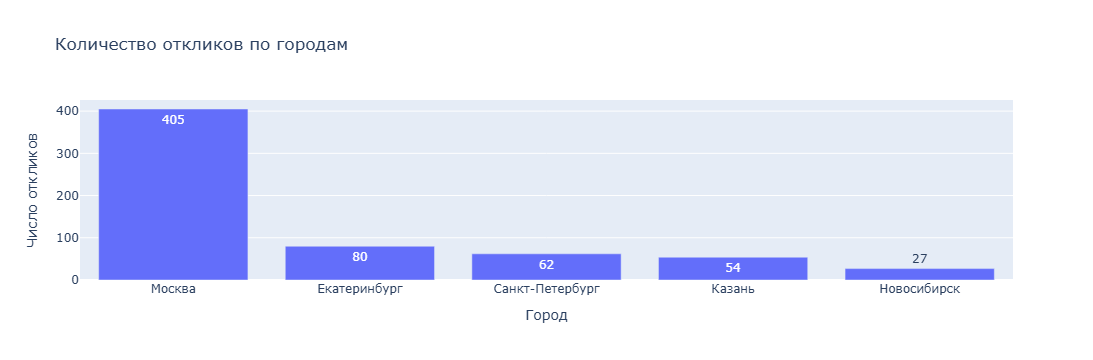

In [24]:
# график
my_chart = px.bar(
    city_report,
    x = "city",
    y = "responses",
    text = "responses", 
    title = "Количество откликов по городам",
    labels = {"city": "Город", "responses": "Число откликов"}
)

my_chart.show()

In [25]:
# сохраняю файл
city_report.to_excel("outputs/vacancies_report_v2.xlsx", index=False)

## 8. Ответьте на три вопроса

Достаточно 1–2 предложений на каждый вопрос.

1. В каком городе больше всего откликов? Сколько там откликов и вакансий?
2. У какой известной группы размера работодателя самая высокая доля приглашений? Укажите долю и числа приглашений и откликов, по которым она рассчитана.
3. Почему полученную медиану нельзя назвать «медианной зарплатой всех вакансий»? Укажите, какие значения использованы и какие не вошли в расчёт.

**Готовность основной части:** есть таблица на уровне вакансии, два отчёта, форматированная таблица, график, Excel-файл и три ответа. Контрольные количества совпадают.

In [26]:
# для 1 вопроса проверяю гипотезу, действительно ли Москва самый крупный рынок труда в этой выборке
moscow_vacancy = city_report.loc[city_report["city"] == "Москва", "vacancies"].values[0]
moscow_responses = city_report.loc[city_report["city"] == "Москва", "responses"].values[0]

# считаю общее количество откликов по всем городам
total_vacancy = city_report["vacancies"].sum()
total_responses = city_report["responses"].sum()

print(f"Доля Москвы по вакансиям: {moscow_vacancy / total_vacancy:.1%}")
print(f"Доля Москвы по откликам: {moscow_responses / total_responses:.1%}")

Доля Москвы по вакансиям: 50.0%
Доля Москвы по откликам: 64.5%


**Ваши ответы:**

1. Больше всего откликов в Москве - **405 откликов** на 26 вакансий. На Москву приходится ровно 50% всех вакансий и 64.5% всех откликов в выборке, что подтверждает ее статус, как самого крупного рынка труда в данных.
2. Среди известных групп самая высокая доля приглашений у **medium**. Доля составляет **18.6%**. Она рассчитана на основе **25 приглашений** и **134 откликов** в этой группе. Группу unknown в сравнение не включаю, так как размер компании неизвестен.
3. Медиана не может так называться, потому что **использованы** значения нижней границы зарплаты (salary_from) в рублях (валюта RUR). А **не вошли в расчет** значения 8 вакансий, у которых изначально не указана ни валюта, ни сумма зарплаты.

## Дополнительно, по желанию

### А. Сводная «город × размер работодателя»

По `df` постройте широкую таблицу: строки — `city`, столбцы — `size_group`, значения — количество `vacancy_id`. Отсутствующие сочетания заполните нулями.

**Метод:** `pivot_table`, агрегатная функция `count`.

### Б. Второй график

Постройте столбчатую диаграмму доли приглашений по `size_report`, исключив `unknown`. Добавьте в подсказку при наведении `invited` и `responses`, чтобы вместе с долей видеть объём данных.

**Методы:** фильтр по условию, `px.bar`, `hover_data`.

Эти два упражнения не нужны для завершения основной части.

In [27]:
# Дополнительно А. Сводная таблица
pivot_city_size = df.pivot_table(
    index = "city", 
    columns = "size_group", 
    values = "vacancy_id", 
    aggfunc = "count",
    fill_value = 0 
)
pivot_city_size

size_group,large,medium,small,unknown
city,,,,
Екатеринбург,0,7,0,0
Казань,1,0,3,0
Москва,17,0,7,2
Новосибирск,4,0,2,0
Санкт-Петербург,3,6,0,0


**Вывод:**

1. Крупный бизнес сконцентрирован в Москве (17 вакансий), тогда как в регионах (Екатеринбург, Санкт-Петербург) преобладает средний бизнес. В Москве 2. средний бизнес вообще не представлен.
2. Группа unknown встречается только в Москве (2 вакансии), что соответствует вакансиям компании «Стартап Ноль».

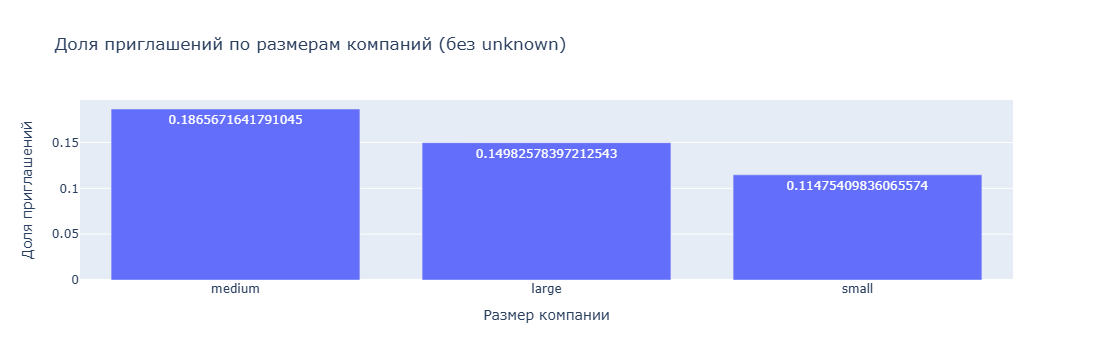

In [28]:
# Дополнительно Б. Доли приглашений на графике
# исключаю unkhown
known_sizes = size_report[size_report["size_group"] != "unknown"]

my_chart2 = px.bar(
    known_sizes,
    x = "size_group",
    y = "invitation_share",
    text = "invitation_share",             
    hover_data = ["invited", "responses"],   # подсказка при наведении 
    title = "Доля приглашений по размерам компаний (без unknown)",
    labels = {"size_group": "Размер компании", "invitation_share": "Доля приглашений"}
)

my_chart2.show()

## Бонус, про который я чуть не забыл)

Честно говоря, когда я только начал делать дз, я прочитал все через read_csv, чтобы быстрее перейти к основной части.

Но потом вспомнил про бонус... Я прочитал данные из SQL с помощью цикла и упаковал их в словарь tables_from_sql.

Я вывел ниже таблицу со звонками, просто чтобы показать, что база реально работает и возвращает данные. В основной части я оставил CSV, чтобы ничего не сломать, а вот этот кусок чистый бонус для себя.

In [29]:
from sqlalchemy import create_engine

# создаю engine, сгенерированный depseek
DATABASE_URL = 'postgresql://postgres:ee@localhost:5432/postgres'
engine = create_engine(DATABASE_URL)

table_names = [
    "areas", 
    "employers", 
    "vacancies", 
    "vacancy_details", 
    "responses", 
    "calls", 
    "messages"
]

# упаковываю все в словарь
tables_from_sql = {}
for name in table_names:
    query = f"SELECT * FROM hh_school.{name}"
    tables_from_sql[name] = pd.read_sql(query, con=engine)

# проверка, что все окей
for name, frame in tables_from_sql.items():
    print(f"Таблица '{name}': {frame.shape}")
    
tables_from_sql['calls'].head()

Таблица 'areas': (5, 3)
Таблица 'employers': (12, 5)
Таблица 'vacancies': (52, 12)
Таблица 'vacancy_details': (45, 3)
Таблица 'responses': (628, 5)
Таблица 'calls': (251, 10)
Таблица 'messages': (2862, 9)


,call_id,response_id,employer_id,applicant_id,vacancy_id,caller_role,call_duration,status,call_at,call_tags
0,700001,50389.0,103,901193,1020,employer,578.0,successful,2026-03-03 09:30:00,"[voice, connected, outbound, follow_up]"
1,700002,50229.0,103,901096,1009,employer,795.0,successful,2026-07-10 13:00:00,"[voice, connected, outbound, follow_up]"
2,700003,50180.0,103,900700,1008,employer,375.0,successful,2026-03-30 10:40:00,"[voice, connected, outbound, details]"
3,700004,50509.0,104,900982,1037,applicant,268.0,successful,2026-05-27 16:50:00,"[voice, connected, inbound, follow_up]"
4,700005,50156.0,102,900861,1006,applicant,171.0,successful,2026-07-20 10:10:00,"[voice, connected, inbound, screening]"
